In [21]:
from pathlib import Path
import platform
import random
import timeit
import math
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use("seaborn-v0_8-whitegrid")
print(f"Python {platform.python_version()} | {platform.system()} {platform.machine()}")
print(f"pandas {pd.__version__}")


Python 3.12.3 | Windows AMD64
pandas 2.2.2


# Loading in Iris data(small data set)

In [3]:
COLUMNS = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
DATA_PATH = Path("iris.data")

def load_iris(filename):
    """Read the headerless Iris data file into a validated DataFrame."""
    frame = pd.read_csv(filename, header=None)
    if frame.shape[1] != 5:
        raise ValueError("Expected four measurements and one species column.")
    frame.columns = COLUMNS
    for column in COLUMNS[:4]:
        frame[column] = pd.to_numeric(frame[column], errors="raise")
    if frame.empty or frame.isna().any().any():
        raise ValueError("The dataset is empty or contains missing values.")
    frame["species"] = frame["species"].str.strip()
    return frame

iris = load_iris(DATA_PATH)
print(f"Loaded {len(iris)} records")
display(iris.head())

Loaded 150 records


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
# Dataset statistics: these describe flower measurements, not runtime.
display(iris.describe().round(3))
display(iris["species"].value_counts().rename_axis("species").to_frame("count"))

,sepal_length,sepal_width,petal_length,petal_width
count,150.000,150.000,150.000,150.000
mean,5.843,3.054,3.759,1.199
std,0.828,0.434,1.764,0.763
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


,count
species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


# Loading in Skin Segmentation data(large data set)

In [28]:
COLUMNS = ["Blue", "Green", "Red", "Class"]
DATA_PATH = Path("Skin_NonSkin.txt")

def load_skin(filename):
    frame = pd.read_csv(filename, sep=r"\s+", header=None)
    if frame.shape[1] != 4 or frame.empty or frame.isna().any().any():
        raise ValueError("Expected four nonempty columns with no missing values.")
    frame.columns = COLUMNS
    for field in COLUMNS:
        values = pd.to_numeric(frame[field], errors="raise")
        if not ((values % 1) == 0).all():
            raise ValueError("Expected integer values.")
        frame[field] = values.astype("int64")
    if not frame[COLUMNS[:3]].apply(lambda col: col.between(0, 255).all()).all():
        raise ValueError("Color values must lie between 0 and 255.")
    if not frame["Class"].isin([1, 2]).all():
        raise ValueError("Unexpected class label.")
    return frame

skin = load_skin(DATA_PATH)
print(f"Loaded {len(skin):,} records; {len(skin) / 150:,.1f} times the size of Iris")
display(skin.head())
display(skin[COLUMNS[:3]].describe().round(3))
display(skin["Class"].value_counts().sort_index().to_frame("records"))

Loaded 245,057 records; 1,633.7 times the size of Iris


,Blue,Green,Red,Class
0,74,85,123,1
1,73,84,122,1
2,72,83,121,1
3,70,81,119,1
4,70,81,119,1


,Blue,Green,Red
count,245057.000,245057.000,245057.000
mean,125.065,132.507,123.177
std,62.256,59.941,72.562
min,0.000,0.000,0.000
25%,68.000,87.000,70.000
50%,139.000,153.000,128.000
75%,176.000,177.000,164.000
max,255.000,255.000,255.000


,records
Class,
1,50859
2,194198


# Sorting Functions:

## Merge sort

In [5]:
def merge_sort(data, column=0):
    """Return records in ascending order by column, preserving ties."""
    if len(data) <= 1:
        return data[:]

    middle = len(data) // 2
    left = merge_sort(data[:middle], column)
    right = merge_sort(data[middle:], column)

    merged = []
    i = j = 0
    while i < len(left) and j < len(right):
        if left[i][column] <= right[j][column]:
            merged.append(left[i])
            i += 1
        else:
            merged.append(right[j])
            j += 1

    merged.extend(left[i:])
    merged.extend(right[j:])
    return merged

## Heapsort

In [13]:
def heap_sort(data, column=0):
    result = data[:]
    n = len(result)

    def sift_down(root, size):
        while 2 * root + 1 < size:
            child = 2 * root + 1
            if child + 1 < size and result[child][column] < result[child + 1][column]:
                child += 1
            if result[root][column] >= result[child][column]:
                break
            result[root], result[child] = result[child], result[root]
            root = child

    for root in range(n // 2 - 1, -1, -1):
        sift_down(root, n)
    for end in range(n - 1, 0, -1):
        result[0], result[end] = result[end], result[0]
        sift_down(0, end)
    return result

## Quicksort

In [14]:
def quick_sort(data, column=0):
    result = data[:]
    stack = [(0, len(result) - 1)]
    while stack:
        low, high = stack.pop()
        if low >= high:
            continue
        pivot = result[(low + high) // 2][column]
        less = current = low
        greater = high
        while current <= greater:
            value = result[current][column]
            if value < pivot:
                result[less], result[current] = result[current], result[less]
                less += 1
                current += 1
            elif value > pivot:
                result[current], result[greater] = result[greater], result[current]
                greater -= 1
            else:
                current += 1
        stack.append((low, less - 1))
        stack.append((greater + 1, high))
    return result

## Insertion sort

In [15]:
def insertion_sort(data, column=0):
    result = data[:]
    for i in range(1, len(result)):
        record = result[i]
        j = i - 1
        while j >= 0 and result[j][column] > record[column]:
            result[j + 1] = result[j]
            j -= 1
        result[j + 1] = record
    return result

## Radix sort

In [16]:
def radix_sort(data, column=0):
    items = []
    for record in data:
        value = record[column]
        if not math.isfinite(value) or value < 0:
            raise ValueError("Radix sort requires finite nonnegative measurements.")
        scaled = value * 10
        key = round(scaled)
        if not math.isclose(scaled, key, rel_tol=0, abs_tol=1e-8):
            raise ValueError("Radix sort supports at most one decimal place.")
        items.append((key, record))
    if not items:
        return []

    maximum = max(key for key, _ in items)
    place = 1
    while maximum // place > 0:
        buckets = [[] for _ in range(10)]
        for key, record in items:
            digit = (key // place) % 10
            buckets[digit].append((key, record))
        items = [item for bucket in buckets for item in bucket]
        place *= 10
    return [record for _, record in items]

# Benchmarks

## Iris Benchmark

In [23]:
BATCHES = 30
SORTS_PER_BATCH = 200
WARMUP = 100

jobs = [(name, function, column, field)
        for name, function in ALGORITHMS.items()
        for column, field in enumerate(COLUMNS[:4])]
for name, function, column, field in jobs:
    for _ in range(WARMUP):
        function(records, column)

measurements = []
rng = random.Random(42)
for batch in range(1, BATCHES + 1):
    scheduled_jobs = jobs[:]
    rng.shuffle(scheduled_jobs)
    for name, function, column, field in scheduled_jobs:
        seconds = timeit.timeit(
            lambda function=function, column=column: function(records, column),
            number=SORTS_PER_BATCH
        )
        measurements.append({
            "algorithm": name, "column": field, "batch": batch,
            "ms_per_sort": seconds * 1000 / SORTS_PER_BATCH
        })

timings = pd.DataFrame(measurements)
summary = timings.groupby(["algorithm", "column"])["ms_per_sort"].describe()
summary = summary.rename(columns={"count": "batches", "min": "fastest_batch_avg", "max": "slowest_batch_avg"})
summary = summary.reindex(pd.MultiIndex.from_product([ALGORITHMS, COLUMNS[:4]], names=["algorithm", "column"]))
print(f"{BATCHES * SORTS_PER_BATCH:,} timed sorts per algorithm per column")
print("Runtime statistics: milliseconds per sort")
display(summary.round(6))

6,000 timed sorts per algorithm per column
Runtime statistics: milliseconds per sort


batches      mean       std  fastest_batch_avg  \
algorithm      column                                                         
Merge sort     sepal_length     30.0  0.239742  0.013210           0.223941   
               sepal_width      30.0  0.263831  0.093804           0.227545   
               petal_length     30.0  0.249656  0.086521           0.216557   
               petal_width      30.0  0.231507  0.013448           0.214689   
Heapsort       sepal_length     30.0  0.229170  0.019476           0.208231   
               sepal_width      30.0  0.211454  0.022918           0.197424   
               petal_length     30.0  0.225173  0.015264           0.205508   
               petal_width      30.0  0.214429  0.016588           0.195606   
Quicksort      sepal_length     30.0  0.089257  0.012000           0.077146   
               sepal_width      30.0  0.068201  0.004914           0.062103   
               petal_length     30.0  0.092745  0.010100           0.083514   
               petal_width      30.0  0.075430  0.020339           0.063370   
Insertion sort sepal_length     30.0  0.224308  0.015065           0.207417   
               sepal_width      30.0  0.589636  0.070605           0.528978   
               petal_length     30.0  0.170499  0.014773           0.154348   
               petal_width      30.0  0.167434  0.082526           0.132370   
Radix sort     sepal_length     30.0  0.112810  0.014154           0.100919   
               sepal_width      30.0  0.108181  0.007976           0.100635   
               petal_length     30.0  0.113437  0.013238           0.099747   
               petal_width      30.0  0.111272  0.011929           0.101743   

                                  25%       50%       75%  slowest_batch_avg  
algorithm      column                                                         
Merge sort     sepal_length  0.230118  0.235235  0.246470           0.274543  
               sepal_width   0.236154  0.244753  0.257912           0.755372  
               petal_length  0.227399  0.231291  0.243994           0.704021  
               petal_width   0.222943  0.229135  0.235127           0.267595  
Heapsort       sepal_length  0.216212  0.223657  0.232187           0.289081  
               sepal_width   0.203059  0.206071  0.210841           0.325516  
               petal_length  0.214036  0.221506  0.229329           0.262783  
               petal_width   0.202981  0.210218  0.220150           0.256254  
Quicksort      sepal_length  0.079979  0.085449  0.092312           0.126550  
               sepal_width   0.065148  0.067033  0.069596           0.081664  
               petal_length  0.086061  0.088262  0.094270           0.121890  
               petal_width   0.066206  0.067683  0.075408           0.163433  
Insertion sort sepal_length  0.214626  0.220773  0.227079           0.277715  
               sepal_width   0.544354  0.563737  0.607064           0.798100  
               petal_length  0.162095  0.166176  0.173752           0.216479  
               petal_width   0.136536  0.140854  0.144475           0.484164  
Radix sort     sepal_length  0.103004  0.106688  0.116718           0.161530  
               sepal_width   0.104403  0.106359  0.108407           0.141801  
               petal_length  0.104519  0.109028  0.117630           0.149395  
               petal_width   0.104496  0.106694  0.112649           0.149172

In [25]:
mean_times = timings.pivot_table(index="algorithm", columns="column", values="ms_per_sort", aggfunc="mean")
mean_times = mean_times.reindex(index=list(ALGORITHMS), columns=COLUMNS[:4])
print("Mean runtime comparison (ms/sort)")
display(mean_times.round(6))

Mean runtime comparison (ms/sort)


column,sepal_length,sepal_width,petal_length,petal_width
algorithm,,,,
Merge sort,0.239742,0.263831,0.249656,0.231507
Heapsort,0.229170,0.211454,0.225173,0.214429
Quicksort,0.089257,0.068201,0.092745,0.075430
Insertion sort,0.224308,0.589636,0.170499,0.167434
Radix sort,0.112810,0.108181,0.113437,0.111272


## Compare runtime visually

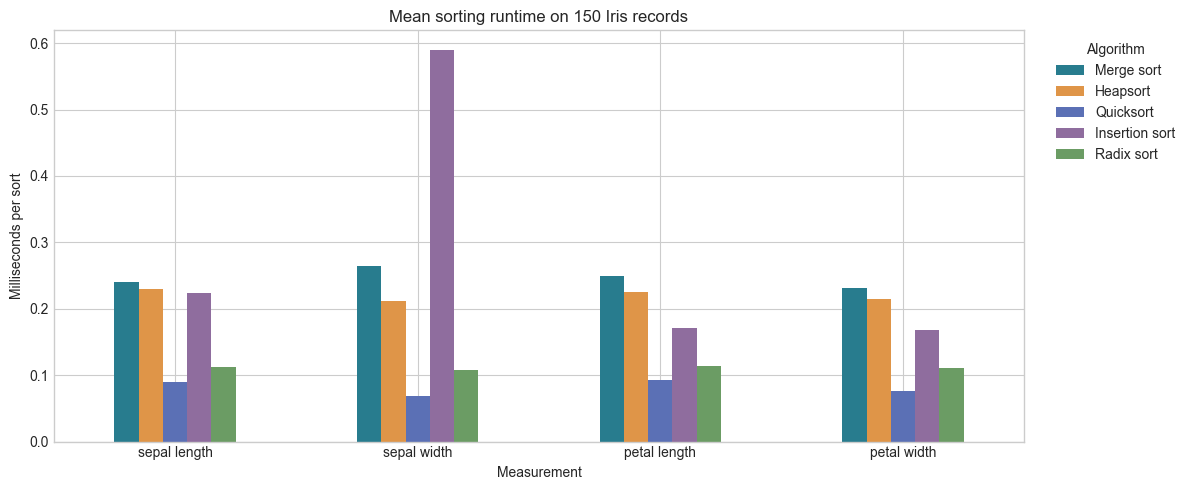

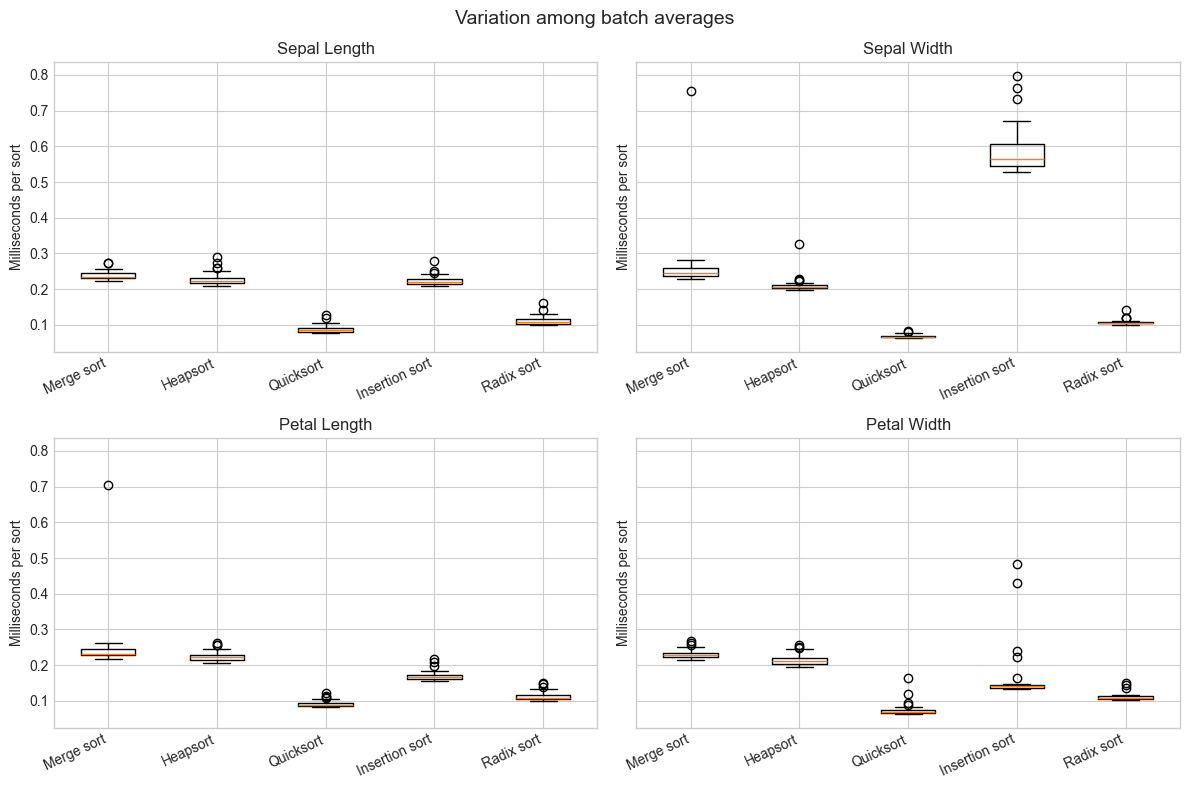

In [26]:
colors = ["#287C8E", "#DF9548", "#5B70B5", "#8F6D9E", "#6B9C64"]
ax = mean_times.T.rename_axis("Measurement").plot.bar(figsize=(12, 5), color=colors, rot=0)
ax.set_title("Mean sorting runtime on 150 Iris records")
ax.set_ylabel("Milliseconds per sort")
ax.set_xticklabels([name.replace("_", " ") for name in COLUMNS[:4]])
ax.legend(title="Algorithm", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
for ax, field in zip(axes.flat, COLUMNS[:4]):
    samples = [timings.loc[(timings["algorithm"] == name) & (timings["column"] == field), "ms_per_sort"].to_numpy()
               for name in ALGORITHMS]
    ax.boxplot(samples)
    ax.set_xticks(range(1, 6), list(ALGORITHMS), rotation=25, ha="right")
    ax.set_title(field.replace("_", " ").title())
    ax.set_ylabel("Milliseconds per sort")
fig.suptitle("Variation among batch averages", fontsize=14)
fig.tight_layout()
plt.show()

## Skin Segmentation Benchmark

In [50]:
ALGORITHMS = {
    "Merge sort": merge_sort, "Heapsort": heap_sort, "Quicksort": quick_sort,
    "Insertion sort": insertion_sort, "Radix sort": radix_sort,
}
STABLE = {"Merge sort", "Insertion sort", "Radix sort"}

REPEATS = 3

MEDIUM_SIZE = min(10_000, len(skin))
LARGE_SIZE = min(100_000, len(skin))
INSERTION_MAX_ROWS = 100_000

# Select 100,000 records once.
large_frame = skin.sample(n=LARGE_SIZE, random_state=42)

# Use the first 10,000 of those records for the medium sample.
medium_frame = large_frame.iloc[:MEDIUM_SIZE]

medium_sample = list(
    medium_frame.itertuples(index=False, name=None)
)

large_sample = list(
    large_frame.itertuples(index=False, name=None)
)

DATASETS = {
    "Medium sample": medium_sample,
    "Large sample": large_sample
}

# Verify the actual sizes before running the benchmarks.
for name, rows in DATASETS.items():
    print(f"{name}: {len(rows):,} records")
    
def validate_sort(name, function, rows, column):
    before = rows[:]
    result = function(rows, column)
    assert [r[column] for r in result] == sorted(r[column] for r in rows)
    assert Counter(result) == Counter(rows)
    assert rows == before
    if name in STABLE:
        assert result == sorted(rows, key=lambda r: r[column])

for name, function in ALGORITHMS.items():
    for case in [[], [(0, "a")], [(255, "a"), (0, "b"), (255, "c"), (12, "d")]]:
        validate_sort(name, function, case, 0)
print("Boundary-case checks passed. Each benchmark combination is also checked before timing.")

Medium sample: 10,000 records
Large sample: 100,000 records
Boundary-case checks passed. Each benchmark combination is also checked before timing.


In [51]:
jobs = []
status = []
for experiment, rows in DATASETS.items():
    for name, function in ALGORITHMS.items():
        for column, field in enumerate(COLUMNS[:3]):
            if name == "Insertion sort" and len(rows) > INSERTION_MAX_ROWS:
                status.append({"experiment": experiment, "rows": len(rows), "algorithm": name,
                               "column": field, "status": "SKIPPED: above configured insertion limit"})
                continue
            validate_sort(name, function, rows, column)
            jobs.append((experiment, rows, name, function, column, field))
            status.append({"experiment": experiment, "rows": len(rows) , "algorithm": name,
                           "column": field, "status": "PASS: correctness checked; benchmark scheduled"})

measurements = []
rng = random.Random(42)
for trial in range(1, REPEATS + 1):
    scheduled = jobs[:]
    rng.shuffle(scheduled)
    for experiment, rows, name, function, column, field in scheduled:
        seconds = timeit.timeit(lambda function=function, rows=rows, column=column: function(rows, column), number=1)
        measurements.append({"experiment": experiment, "rows": len(rows) , "algorithm": name,
                             "column": field, "trial": trial, "seconds": seconds})
    print(f"Completed trial {trial}/{REPEATS}")

timings = pd.DataFrame(measurements)
status_table = pd.DataFrame(status)
status_table["status"] = status_table["status"].str.replace("benchmark scheduled", "benchmark completed", regex=False)
display(status_table)
summary = timings.groupby(["experiment", "rows", "algorithm", "column"])["seconds"].describe()
print("Individual-sort runtime statistics, in seconds")
display(summary.round(6))

Completed trial 1/3
Completed trial 2/3
Completed trial 3/3


,experiment,rows,algorithm,column,status
0,Medium sample,10000,Merge sort,Blue,PASS: correctness checked; benchmark completed
1,Medium sample,10000,Merge sort,Green,PASS: correctness checked; benchmark completed
2,Medium sample,10000,Merge sort,Red,PASS: correctness checked; benchmark completed
3,Medium sample,10000,Heapsort,Blue,PASS: correctness checked; benchmark completed
4,Medium sample,10000,Heapsort,Green,PASS: correctness checked; benchmark completed
5,Medium sample,10000,Heapsort,Red,PASS: correctness checked; benchmark completed
6,Medium sample,10000,Quicksort,Blue,PASS: correctness checked; benchmark completed
7,Medium sample,10000,Quicksort,Green,PASS: correctness checked; benchmark completed
8,Medium sample,10000,Quicksort,Red,PASS: correctness checked; benchmark completed
9,Medium sample,10000,Insertion sort,Blue,PASS: correctness checked; benchmark completed


Individual-sort runtime statistics, in seconds


count        mean        std  \
experiment    rows   algorithm      column                                 
Large sample  100000 Heapsort       Blue      3.0    0.691473   0.121393   
                                    Green     3.0    0.591326   0.097116   
                                    Red       3.0    0.580568   0.118451   
                     Insertion sort Blue      3.0  470.000778  11.653002   
                                    Green     3.0  514.085549  42.225585   
                                    Red       3.0  498.090950  26.345635   
                     Merge sort     Blue      3.0    0.417863   0.010543   
                                    Green     3.0    0.385681   0.024795   
                                    Red       3.0    0.417848   0.054968   
                     Quicksort      Blue      3.0    0.184540   0.026493   
                                    Green     3.0    0.178157   0.012056   
                                    Red       3.0    0.173113   0.031437   
                     Radix sort     Blue      3.0    0.237564   0.011414   
                                    Green     3.0    0.321912   0.152141   
                                    Red       3.0    0.237797   0.007879   
Medium sample 10000  Heapsort       Blue      3.0    0.056464   0.031935   
                                    Green     3.0    0.064734   0.050244   
                                    Red       3.0    0.037936   0.004486   
                     Insertion sort Blue      3.0    3.911933   0.776107   
                                    Green     3.0    3.171646   0.329829   
                                    Red       3.0    3.199056   0.257992   
                     Merge sort     Blue      3.0    0.044141   0.025373   
                                    Green     3.0    0.033464   0.003708   
                                    Red       3.0    0.037899   0.004886   
                     Quicksort      Blue      3.0    0.012906   0.001101   
                                    Green     3.0    0.013621   0.004211   
                                    Red       3.0    0.011961   0.000608   
                     Radix sort     Blue      3.0    0.015281   0.004136   
                                    Green     3.0    0.018220   0.004213   
                                    Red       3.0    0.016187   0.002990   

                                                   min         25%  \
experiment    rows   algorithm      column                           
Large sample  100000 Heapsort       Blue      0.551887    0.651036   
                                    Green     0.483009    0.551677   
                                    Red       0.509305    0.512201   
                     Insertion sort Blue    460.096536  463.580673   
                                    Green   465.541477  499.974386   
                                    Red     470.934533  485.364902   
                     Merge sort     Blue      0.406039    0.413653   
                                    Green     0.367920    0.371518   
                                    Red       0.366699    0.388787   
                     Quicksort      Blue      0.158041    0.171297   
                                    Green     0.165744    0.172324   
                                    Red       0.136984    0.162555   
                     Radix sort     Blue      0.230635    0.230977   
                                    Green     0.216712    0.234689   
                                    Red       0.230962    0.233489   
Medium sample 10000  Heapsort       Blue      0.035968    0.038066   
                                    Green     0.033115    0.035766   
                                    Red       0.035152    0.035349   
                     Insertion sort Blue      3.131177    3.526246   
                                    Green     2.895080    2.989124   
                                    Red       2.990831    3.054748   
 

## Visual comparison

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = {"Merge sort": "#287C8E", "Heapsort": "#DF9548", "Quicksort": "#5B70B5",
          "Insertion sort": "#8F6D9E", "Radix sort": "#6B9C64"}
for ax, experiment in zip(axes, DATASETS):
    table = timings[timings["experiment"] == experiment].pivot_table(
        index="column", columns="algorithm", values="seconds", aggfunc="mean")
    present = [name for name in ALGORITHMS if name in table.columns]
    table = table.reindex(index=COLUMNS[:3], columns=present)
    table.plot.bar(ax=ax, color=[colors[name] for name in present], rot=0)
    ax.set_title(f"{experiment}: {len(DATASETS[experiment]):,} rows")
    ax.set_ylabel("Mean seconds per sort")
    ax.set_xlabel("Sort key")
    ax.legend(fontsize=8)
fig.suptitle("Skin/NonSkin: sorting runtime (3 trials per combination)")
fig.tight_layout()
plt.show()